# 07 - EDA bối cảnh kinh tế vĩ mô

Notebook mô tả bối cảnh vĩ mô, chưa đánh giá tương quan với cryptocurrency. Các chuỗi khác đơn vị được vẽ ở subplot riêng để tránh trục kép gây ấn tượng đồng biến giả. Phần xuyên quốc gia dùng đơn vị quốc gia/nền kinh tế/vùng lãnh thổ theo dimension; CPI khác phương pháp giữa các nền kinh tế nên chỉ được diễn giải mô tả, tuyệt đối không suy thành mức chấp nhận cryptocurrency.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd() / "scripts"))
from common import TABLES, FIGURES, QUALITY, ensure_output_dirs, write_csv_atomic
ensure_output_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":120, "savefig.dpi":180, "font.family":"DejaVu Sans"})
macro = pd.read_csv(TABLES / "fact_macro_monthly.csv", parse_dates=["month"])
country = pd.read_csv(TABLES / "fact_country_yearly.csv", keep_default_na=False, na_values=[""])

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show(); plt.close(fig)

## H08 - Các chỉ số vĩ mô theo thời gian

**Vì sao dùng small multiples:** VIX, DXY, CPI YoY và US10Y khác đơn vị và thang đo.
Subplot chung trục thời gian cho phép quan sát bối cảnh mà không ép chuẩn hóa hoặc dùng trục kép
dễ gây ấn tượng đồng biến giả. Hình không phải kiểm định tương quan.

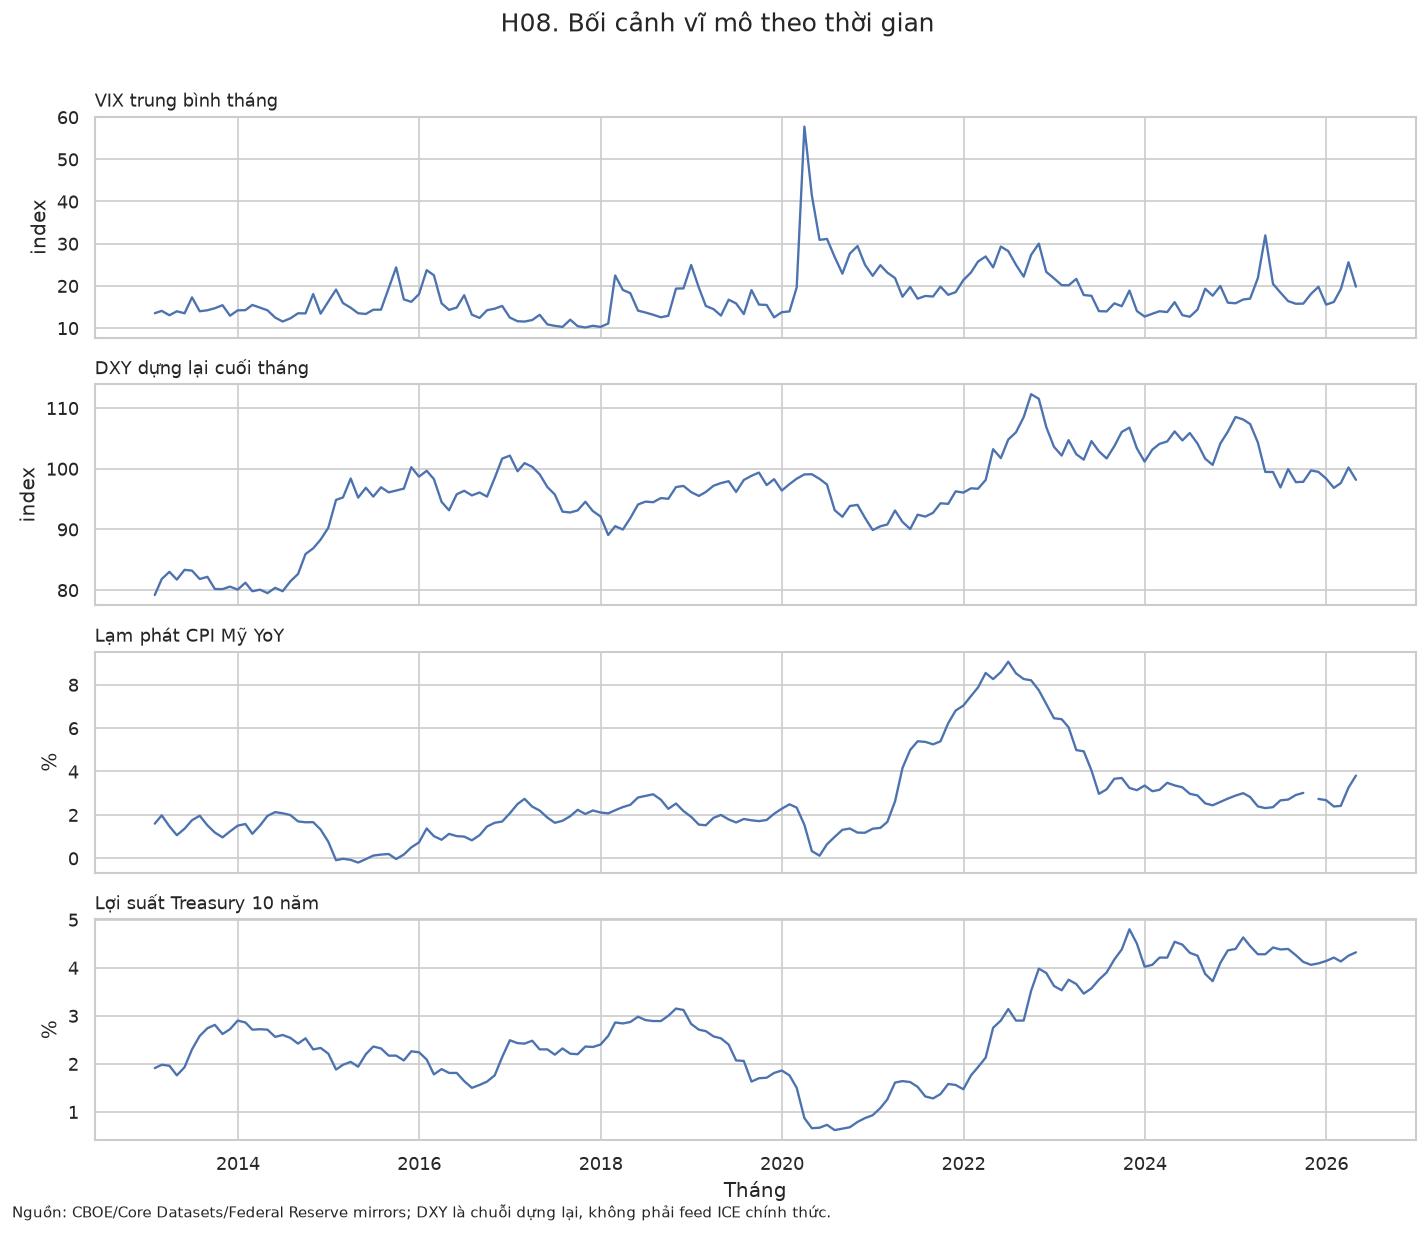

In [2]:
view = macro.loc[macro.month.between("2013-01-31", "2026-04-30")]
series = [
    ("vix_mean","VIX trung bình tháng","index"),
    ("dxy_reconstructed","DXY dựng lại cuối tháng","index"),
    ("cpi_yoy_pct","Lạm phát CPI Mỹ YoY","%"),
    ("us10y_yield_pct","Lợi suất Treasury 10 năm","%"),
]
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (col, title, unit) in zip(axes, series):
    ax.plot(view.month, view[col], linewidth=1.4)
    ax.set_ylabel(unit); ax.set_title(title, loc="left", fontsize=11)
axes[-1].set_xlabel("Tháng")
fig.suptitle("H08. Bối cảnh vĩ mô theo thời gian", y=1.01, fontsize=15)
fig.text(.01, .005, "Nguồn: CBOE/Core Datasets/Federal Reserve mirrors; DXY là chuỗi dựng lại, không phải feed ICE chính thức.", fontsize=9)
save(fig, "H08_boi_canh_vi_mo_small_multiples.png")

## H09 - Phân phối lạm phát theo châu lục năm 2023

**Vì sao dùng boxplot + điểm và symlog:** cần thấy cả phân phối trong từng châu lục lẫn từng nền kinh tế. Lạm phát có giá trị âm và cực đoan; symlog giữ toàn bộ quan sát thay vì cắt outlier. Mốc 10% là ngưỡng mô tả đã định nghĩa, không phải chuẩn pháp lý toàn cầu. Khác biệt rổ CPI/phương pháp thống kê khiến so sánh chỉ mang tính mô tả.

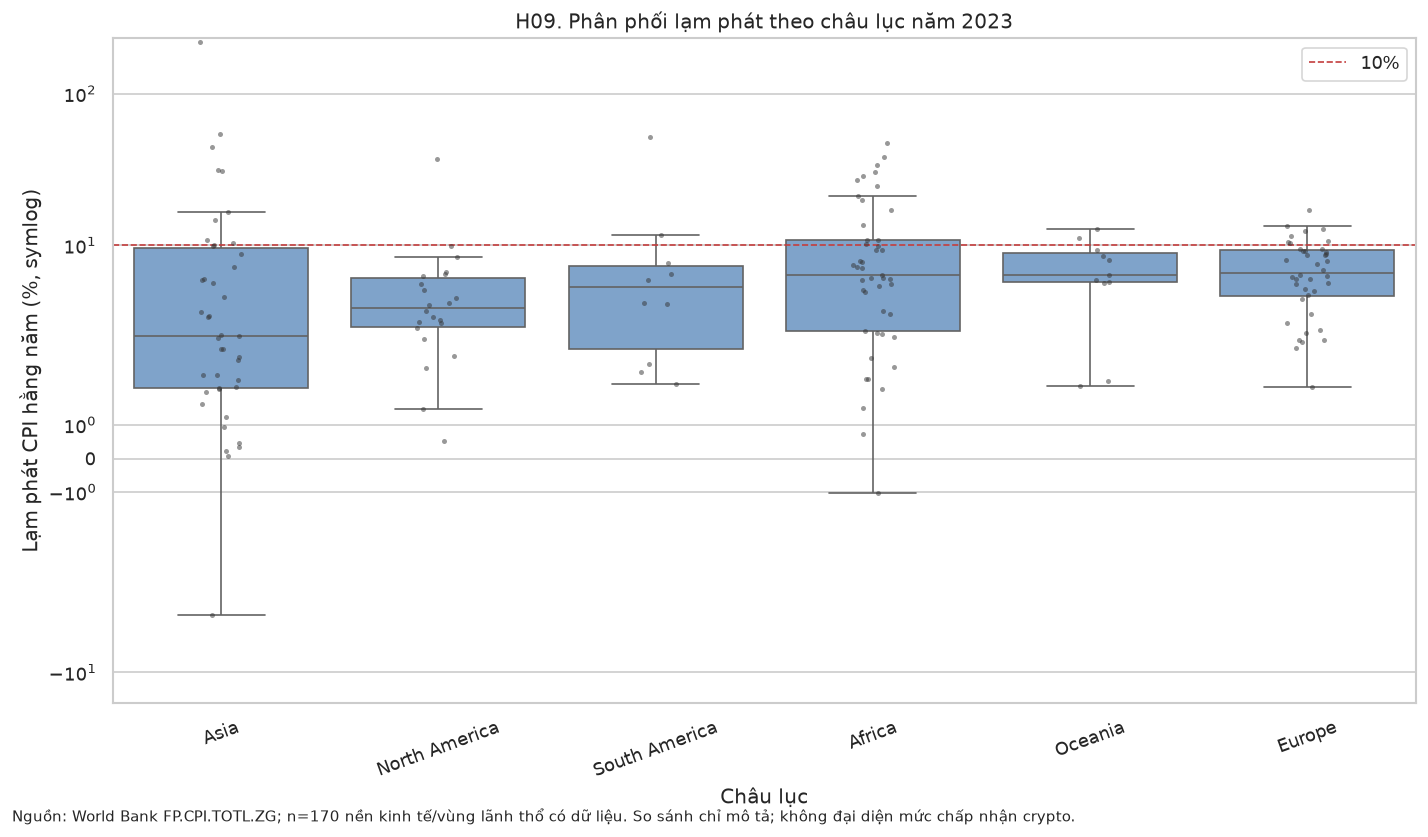

In [3]:
c2023 = country.loc[(country.year.astype(int) == 2023) & country.inflation_annual_pct.notna()].copy()
order = c2023.groupby("continent_name").inflation_annual_pct.median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=c2023, x="continent_name", y="inflation_annual_pct", order=order, showfliers=False, color="#73A2D6", ax=ax)
sns.stripplot(data=c2023, x="continent_name", y="inflation_annual_pct", order=order, color="#333333", alpha=.5, size=3, ax=ax)
ax.axhline(10, color="#C43D3D", linestyle="--", linewidth=1, label="10%")
ax.set_yscale("symlog", linthresh=5)
ax.set_title("H09. Phân phối lạm phát theo châu lục năm 2023")
ax.set_xlabel("Châu lục"); ax.set_ylabel("Lạm phát CPI hằng năm (%, symlog)"); ax.legend()
ax.tick_params(axis="x", rotation=20)
fig.text(.01, .01, f"Nguồn: World Bank FP.CPI.TOTL.ZG; n={len(c2023)} nền kinh tế/vùng lãnh thổ có dữ liệu. So sánh chỉ mô tả; không đại diện mức chấp nhận crypto.", fontsize=9)
save(fig, "H09_lam_phat_quoc_gia_2023.png")

## H10 - GDP đầu người và lạm phát

**Vì sao dùng scatter và log-x/symlog-y:** hai biến định lượng theo cùng grain ISO3-năm; scatter thể hiện độ phân tán và ngoại lệ. GDP/người lệch nhiều bậc nên dùng log; symlog-y giữ giảm phát và siêu lạm phát. Hình chỉ mô tả cắt ngang năm 2023, không chứng minh GDP gây lạm phát hoặc hành vi cryptocurrency.

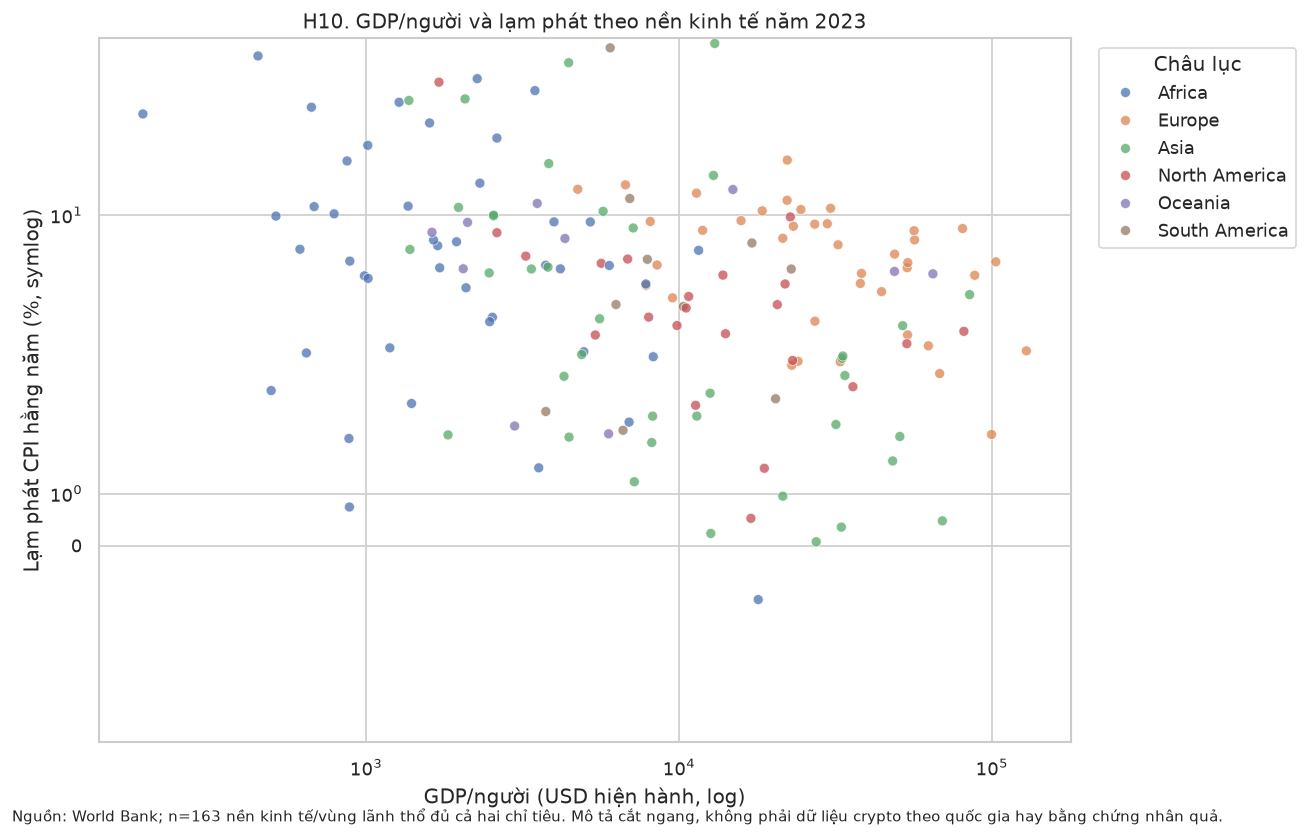

In [4]:
cross = country.loc[(country.year.astype(int) == 2023) & country.gdp_per_capita_usd.notna() & country.inflation_annual_pct.notna()].copy()
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=cross, x="gdp_per_capita_usd", y="inflation_annual_pct", hue="continent_name", alpha=.75, ax=ax)
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=5)
ax.set_title("H10. GDP/người và lạm phát theo nền kinh tế năm 2023")
ax.set_xlabel("GDP/người (USD hiện hành, log)"); ax.set_ylabel("Lạm phát CPI hằng năm (%, symlog)")
ax.legend(title="Châu lục", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(.01, .01, f"Nguồn: World Bank; n={len(cross)} nền kinh tế/vùng lãnh thổ đủ cả hai chỉ tiêu. Mô tả cắt ngang, không phải dữ liệu crypto theo quốc gia hay bằng chứng nhân quả.", fontsize=9)
save(fig, "H10_gdp_lam_phat_2023.png")

In [5]:
context_summary = c2023.groupby("continent_name").agg(
    economies=("iso3", "nunique"),
    median_inflation_pct=("inflation_annual_pct", "median"),
    high_inflation_economies=("high_inflation_ge_10pct", "sum"),
    retained_extreme_inflation=("inflation_extreme_flag", "sum"),
).reset_index()
write_csv_atomic(context_summary, QUALITY / "eda_macro_context_2023.csv")
display(context_summary)

,continent_name,economies,median_inflation_pct,high_inflation_economies,retained_extreme_inflation
0,Africa,45,6.342217,14,0
1,Asia,42,3.656148,9,1
2,Europe,40,6.546696,8,0
3,North America,22,4.477209,1,0
4,Oceania,11,6.351130,2,0
5,South America,10,5.250563,2,0
